In [ ]:
#visualize categorical and numerical data using matplotlib and seaborn
# (boxplot,barchart,histogram,piechart)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer


In [ ]:
# load dataset

cancer = load_breast_cancer()

df = pd.DataFrame(cancer.data,columns=cancer.feature_names) # pyright: ignore[reportAttributeAccessIssue]
df["Diagnosis"] = pd.Series(cancer.target).map({ # pyright: ignore[reportAttributeAccessIssue]
    0: "Malignant",
    1: "Benign"
})

print(df.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

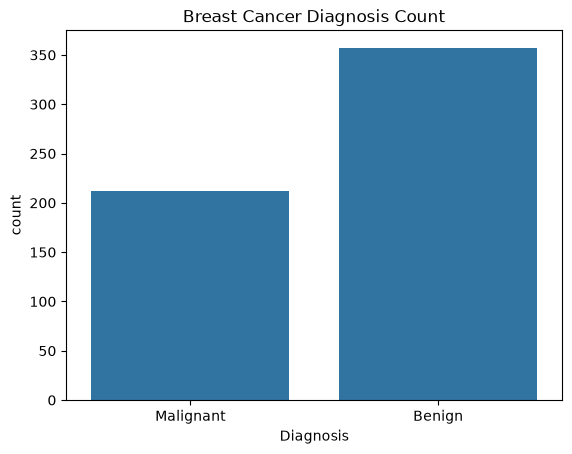


BAR CHART INTERPRETAION
Diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64
Benign cases are more frequent than Malignant cases.


In [3]:
# 1.BAR
count = df["Diagnosis"].value_counts()

sns.countplot(data=df,x="Diagnosis")
plt.title("Breast Cancer Diagnosis Count")
plt.show()

print("\nBAR CHART INTERPRETAION")
print(count)
print("Benign cases are more frequent than Malignant cases.")

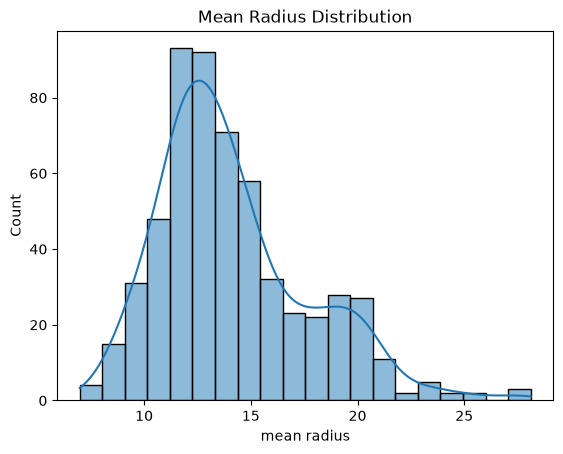


HISTOGRAM INTERPRETATION
Distribution may be positively skewed.:


In [4]:
#2 Histogram
sns.histplot(data=df,x="mean radius",bins=20,kde=True)
plt.title("Mean Radius Distribution")
plt.show()

print("\nHISTOGRAM INTERPRETATION")
mean=df["mean radius"].mean()
median=df["mean radius"].median()


if(mean >median):
    print("Distribution may be positively skewed.:")
elif mean < median:
    print("Distribution may be negatively skewed.:")
else:
    print("Mean and median are equal.:")



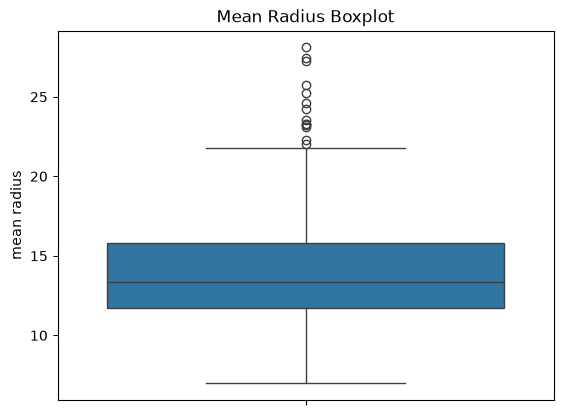


BOXPLOT INTERPRETATION
Median:  13.37
IQR:  4.08
Potential outliers:  555
Boxplot shows median , spread and potential outliers.:


In [5]:
#3 boxplot: Numerical Data
sns.boxplot(data=df,y="mean radius")
plt.title("Mean Radius Boxplot")
plt.show()

print("\nBOXPLOT INTERPRETATION")
q1 = df["mean radius"].quantile(0.25)
q3 = df["mean radius"].quantile(0.75)
iqr = q3-q1

outliers = df[
    (df["mean radius"] < q1- 1.5*iqr) | 
    (df["mean radius"] < q3 + 1.5*iqr)
    ]
print("Median: ",round(median,2))
print("IQR: ",round(iqr,2))
print("Potential outliers: ",len(outliers))
print("Boxplot shows median , spread and potential outliers.:")

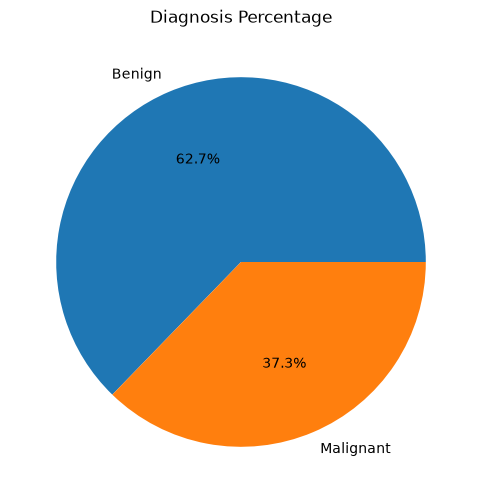


PIE CHART INTERPRETATION
Benign : 62.74 %
Malignant : 37.26 %
Pie chart shows the percentage of each diagnosis category.


In [ ]:
#4 piechart- Categorical data

plt.figure(figsize=(6,6))
plt.pie(count, labels=count.index,autopct="%1.1f%%") # pyright: ignore[reportArgumentType, reportAttributeAccessIssue]
plt.title("Diagnosis Percentage")
plt.show()

print("\nPIE CHART INTERPRETATION")
for cat,value in count.items():
    print(cat,":",round(value/len(df)*100,2),"%")

print("Pie chart shows the percentage of each diagnosis category.")

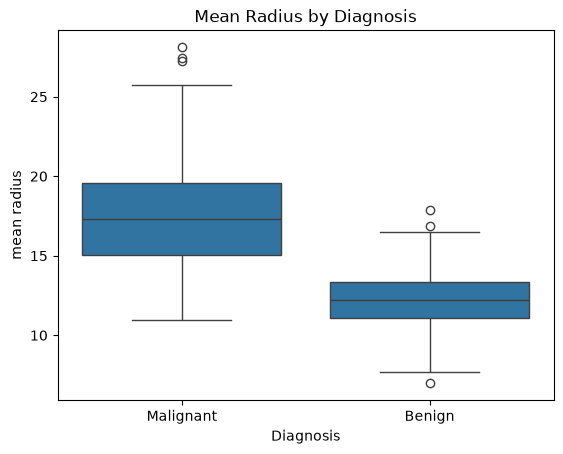


COMPARATIVE BOXPLOT INTERPRETATION
Diagnosis
Benign       12.20
Malignant    17.33
Name: mean radius, dtype: float64
Compare median radius values across both diagnosis groups.


In [7]:
#5 Comparative Boxplot
sns.boxplot(data=df,x="Diagnosis",y="mean radius")
plt.title("Mean Radius by Diagnosis")
plt.show()

print("\nCOMPARATIVE BOXPLOT INTERPRETATION")
print(df.groupby("Diagnosis")["mean radius"].median().round(2))
print("Compare median radius values across both diagnosis groups.")

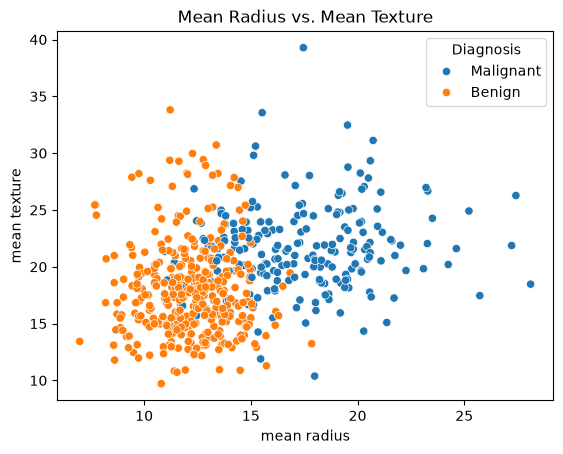


SCATTERPLOT INTERPRETATION
Correlation:  0.324
Positive relationship between the attributes.


In [9]:
# 6. SCATTERPLOT - Multivariate data.
sns.scatterplot(
    data=df,
    x="mean radius",
    y="mean texture",
    hue="Diagnosis"
    )

plt.title("Mean Radius vs. Mean Texture")
plt.show()

print("\nSCATTERPLOT INTERPRETATION")
corr = df["mean radius"].corr(df["mean texture"])
print("Correlation: ", round(corr, 3))
 

if corr >0:
    print("Positive relationship between the attributes.")
elif corr <0:
    print("Positive relationship between the attributes.")
else:
    print("No Linear Correlation")